In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display



# Set the visual style


In [2]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries imported successfully!")

Libraries imported successfully!



# Load the Titanic dataset


In [3]:
df = sns.load_dataset("titanic")
print("First 5 rows of the dataset:")
display(df.head())

First 5 rows of the dataset:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
# Standardize column names if using the alternative dataset
df.columns = df.columns.str.lower().str.strip()

# Standardize common column names
df = df.rename(columns={
    "passengerid": "passenger_id",
    "survived": "survived",
    "pclass": "pclass",
    "sex": "sex",
    "age": "age",
    "sibsp": "sibsp",
    "parch": "parch",
    "fare": "fare",
    "embarked": "embarked"
})

print("Dataset shape (rows, columns):")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset shape (rows, columns):
(891, 15)

Column names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#Find missing values

In [5]:
print("Missing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nMissing value percentage:")
missing_percent = (df.isnull().mean() * 100).round(2)
display(missing_percent.to_frame("Missing Percentage (%)"))

print("\nDuplicate rows:", df.duplicated().sum())

Missing values in each column:


,Missing Values
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0



Missing value percentage:


,Missing Percentage (%)
survived,0.00
pclass,0.00
sex,0.00
age,19.87
sibsp,0.00
parch,0.00
fare,0.00
embarked,0.22
class,0.00
who,0.00



Duplicate rows: 107


In [6]:
for col in ["survived", "sex", "pclass", "embarked"]:
    if col in df.columns:
        print(f"\nValue counts for {col}:")
        display(df[col].value_counts(dropna=False))


Value counts for survived:


,count
survived,
0,549
1,342



Value counts for sex:


,count
sex,
male,577
female,314



Value counts for pclass:


,count
pclass,
3,491
1,216
2,184



Value counts for embarked:


,count
embarked,
S,644
C,168
Q,77
NaN,2


#Histogram — age distribution

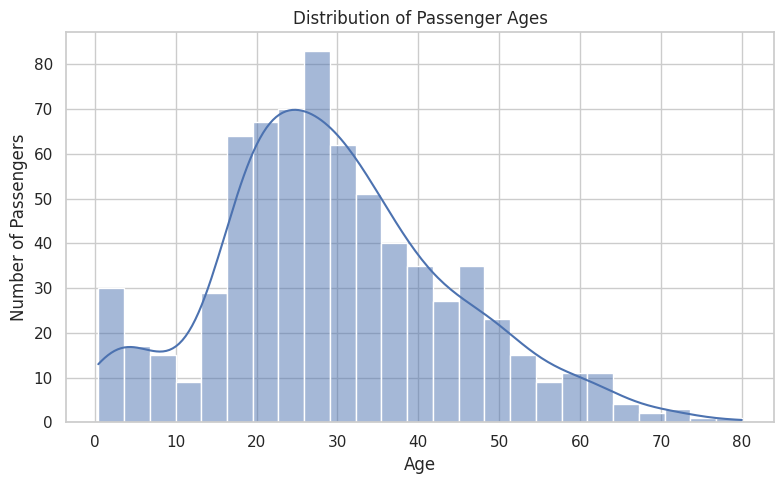

In [7]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="age", bins=25, kde=True)
plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

#Histogram — passenger fares

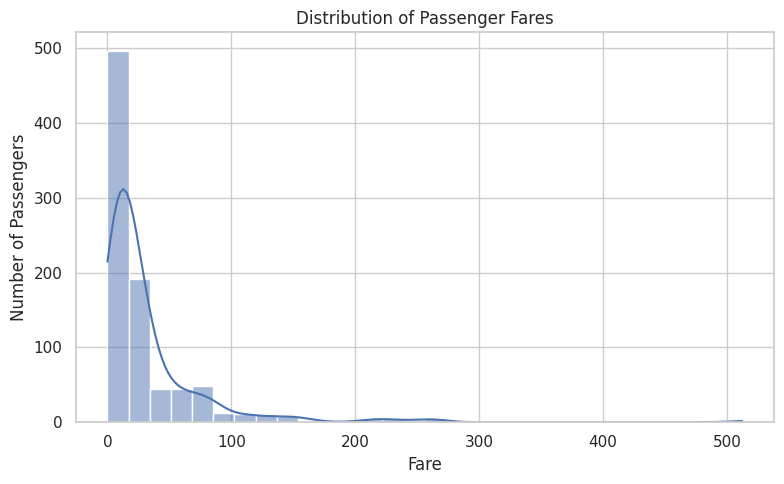

In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="fare", bins=30, kde=True)
plt.title("Distribution of Passenger Fares")
plt.xlabel("Fare")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

#Boxplot — age by survival

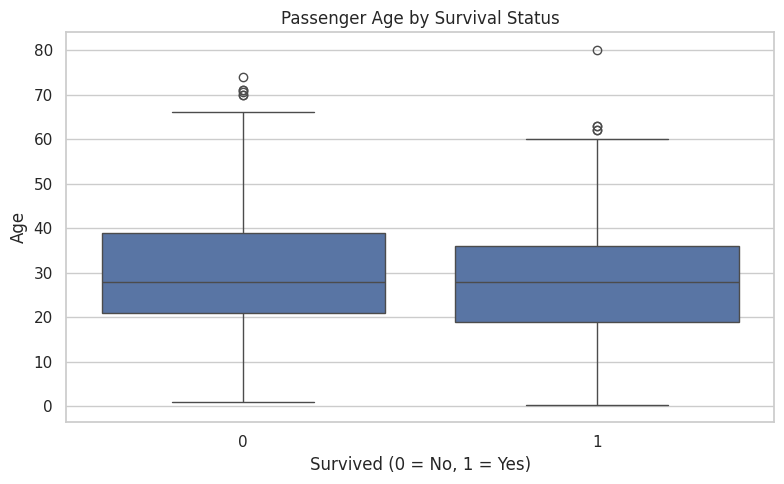

In [9]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="survived", y="age")
plt.title("Passenger Age by Survival Status")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

#Boxplot — fares by passenger class

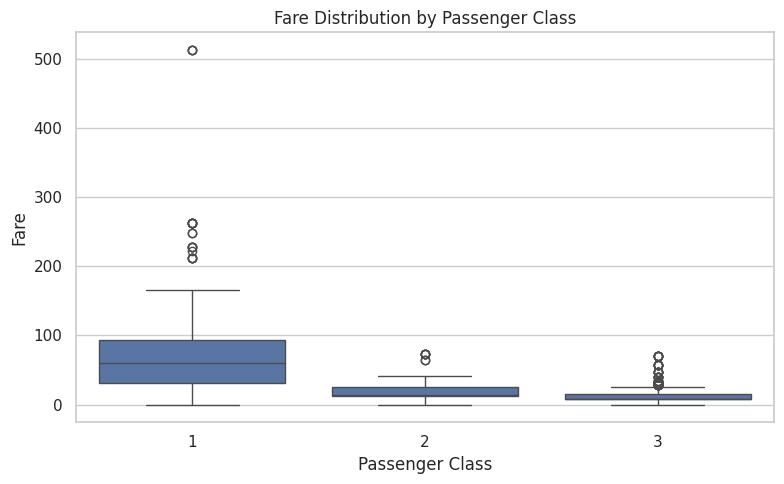

In [10]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="pclass", y="fare")
plt.title("Fare Distribution by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()

#Scatterplot — age versus fare

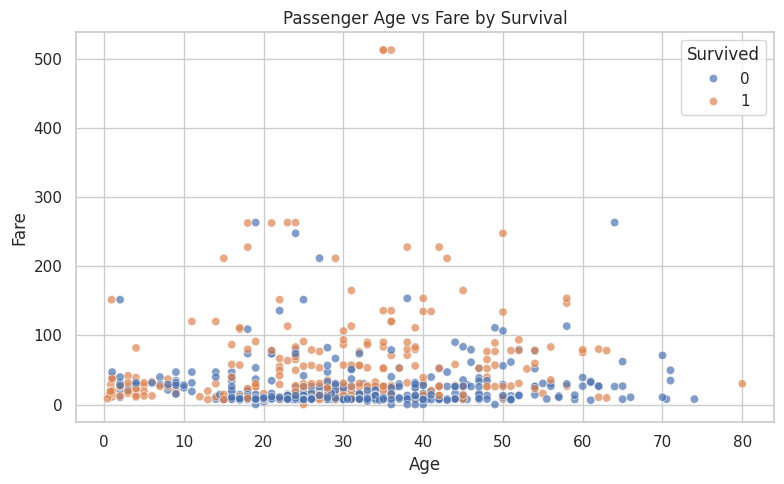

In [11]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="age",
    y="fare",
    hue="survived",
    alpha=0.7
)
plt.title("Passenger Age vs Fare by Survival")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.legend(title="Survived")
plt.tight_layout()
plt.show()

#Countplot — survival count

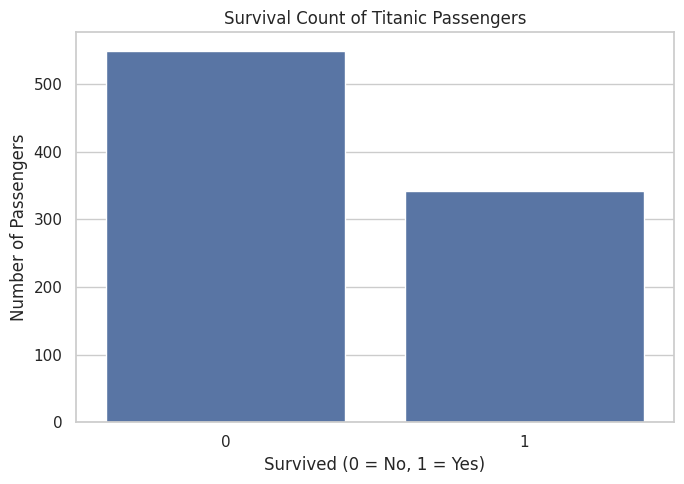

Survival counts:


,count
survived,
0,549
1,342


In [12]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="survived")
plt.title("Survival Count of Titanic Passengers")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

print("Survival counts:")
display(df["survived"].value_counts().sort_index())

#Pairplot — relationships between variables

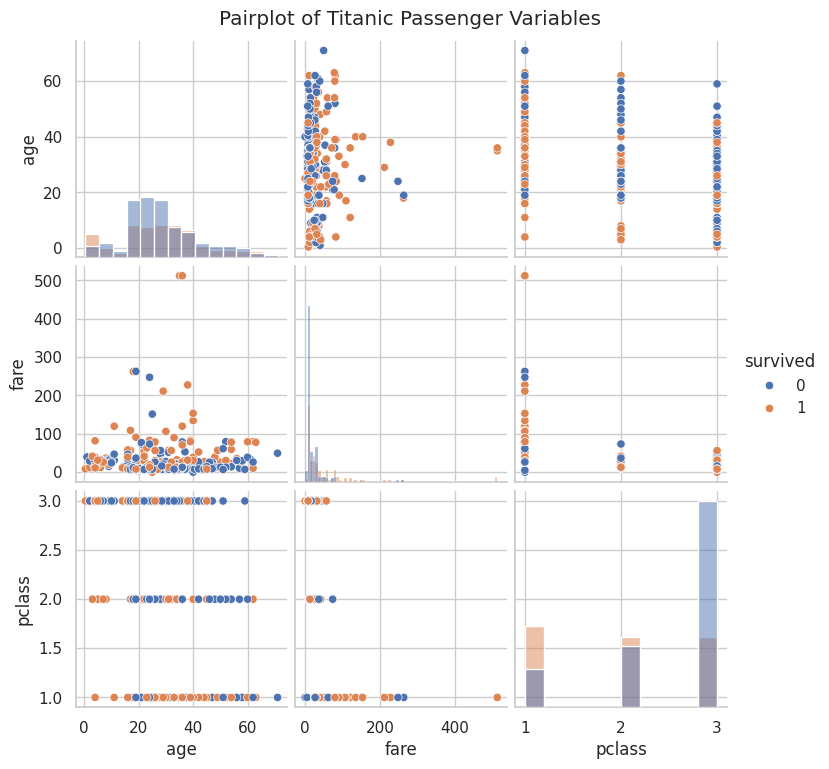

In [13]:
pair_data = df[["age", "fare", "pclass", "survived"]].dropna()

sns.pairplot(
    pair_data.sample(min(300, len(pair_data)), random_state=42),
    hue="survived",
    diag_kind="hist"
)
plt.suptitle("Pairplot of Titanic Passenger Variables", y=1.02)
plt.show()

#Correlation heatmap

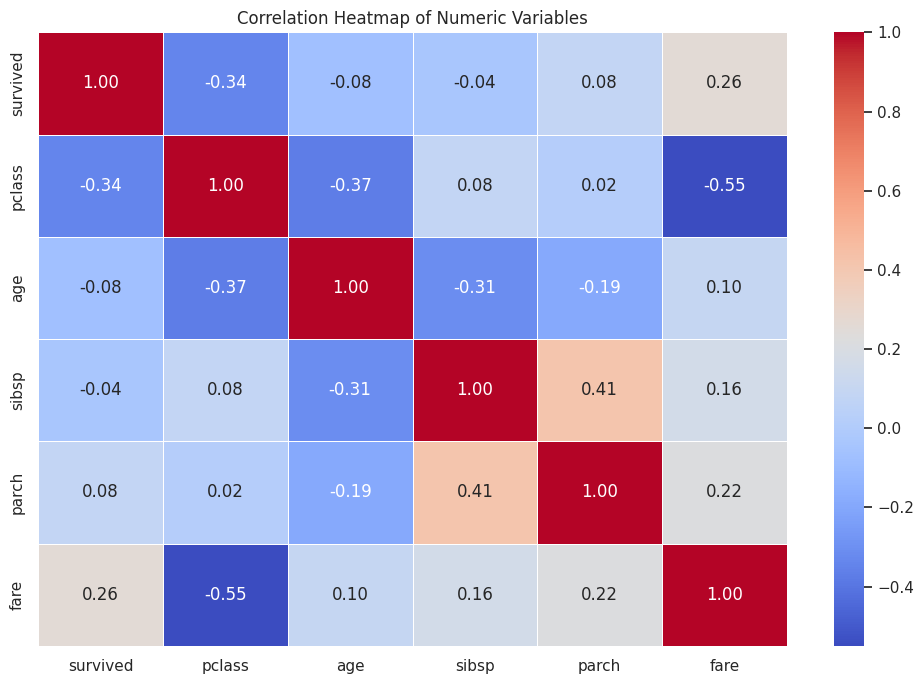

In [14]:
numeric_df = df.select_dtypes(include="number")
correlation = numeric_df.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()

#Calculate survival rates and identify trends

In [15]:
print("Overall survival rate:")
print(f"{df['survived'].mean() * 100:.2f}%")

print("\nSurvival rate by sex:")
display((df.groupby("sex", observed=False)["survived"].mean() * 100).round(2))

print("\nSurvival rate by passenger class:")
display((df.groupby("pclass", observed=False)["survived"].mean() * 100).round(2))

print("\nSurvival rate by age group:")
age_groups = pd.cut(
    df["age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"]
)
display((df.assign(age_group=age_groups)
         .groupby("age_group", observed=False)["survived"]
         .mean() * 100).round(2))

Overall survival rate:
38.38%

Survival rate by sex:


,survived
sex,
female,74.20
male,18.89



Survival rate by passenger class:


,survived
pclass,
1,62.96
2,47.28
3,24.24



Survival rate by age group:


,survived
age_group,
Child,57.97
Teenager,42.86
Young Adult,38.27
Adult,40.00
Senior,22.73


#Exploratory Data Analysis of the Titanic Dataset
##Objective

To explore the Titanic passenger dataset using statistical methods and visualizations to identify patterns, trends, missing values, and relationships between variables.

Tools Used:
Python
Pandas and NumPy
Matplotlib
Seaborn
Google Colab

##Key Observations
Dataset overview: The dataset contains passenger information such as age, sex, passenger class, fare, and survival status.

Missing values: The missing-value analysis identifies columns that require attention before further analysis.

Age distribution: The histogram helps reveal the most common passenger age ranges and the shape of the age distribution.

Fare distribution: The fare histogram and boxplot help identify differences in ticket prices and potential outliers.

Survival patterns: Survival counts and survival rates by sex and passenger class help identify differences between passenger groups.

Relationships: The scatterplot, pairplot, and correlation heatmap help reveal associations among the numeric variables.

##Conclusion

Exploratory Data Analysis helps transform raw data into useful insights. Statistical summaries and visualizations make it easier to understand distributions, detect unusual values, and identify relationships between variables. The Titanic dataset demonstrates how passenger characteristics can be explored in relation to survival. These findings describe associations in the dataset and do not establish causation.

In [16]:

from matplotlib.backends.backend_pdf import PdfPages
from google.colab import files
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

pdf_name = "Task5_Titanic_EDA_Report.pdf"

with PdfPages(pdf_name) as pdf:

    # Page 1: Title and summary
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.suptitle(
        "Exploratory Data Analysis\nTitanic Dataset",
        fontsize=24, fontweight="bold", y=0.90
    )

    summary = f"""
OBJECTIVE
Explore passenger data using statistics and visualizations.

TOOLS
Python, Pandas, Matplotlib, Seaborn, Google Colab

DATASET OVERVIEW
Rows: {df.shape[0]}
Columns: {df.shape[1]}

OVERALL SURVIVAL RATE
{df['survived'].mean() * 100:.2f}%

MISSING VALUES
{int(df.isnull().sum().sum())} missing cells across the dataset.

KEY ANALYSIS
- Passenger age and fare distributions
- Survival counts and survival rates
- Differences between passenger classes
- Relationships among numeric variables

CONCLUSION
EDA helps identify patterns, distributions, missing data,
and associations that can guide further investigation.
"""
    fig.text(0.12, 0.77, summary, fontsize=12,
             va="top", linespacing=1.7)
    plt.axis("off")
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

    # Page 2: Age distribution
    fig, ax = plt.subplots(figsize=(8.27, 5.85))
    sns.histplot(data=df, x="age", bins=25, kde=True, ax=ax)
    ax.set_title("Passenger Age Distribution")
    ax.set_xlabel("Age")
    ax.set_ylabel("Passenger Count")
    fig.tight_layout()
    pdf.savefig(fig)
    plt.close(fig)

    # Page 3: Fare distribution
    fig, ax = plt.subplots(figsize=(8.27, 5.85))
    sns.histplot(data=df, x="fare", bins=30, kde=True, ax=ax)
    ax.set_title("Passenger Fare Distribution")
    ax.set_xlabel("Fare")
    ax.set_ylabel("Passenger Count")
    fig.tight_layout()
    pdf.savefig(fig)
    plt.close(fig)

    # Page 4: Survival count
    fig, ax = plt.subplots(figsize=(8.27, 5.85))
    sns.countplot(data=df, x="survived", ax=ax)
    ax.set_title("Passenger Survival Count")
    ax.set_xlabel("Survived (0 = No, 1 = Yes)")
    ax.set_ylabel("Passenger Count")
    fig.tight_layout()
    pdf.savefig(fig)
    plt.close(fig)

    # Page 5: Age by survival
    fig, ax = plt.subplots(figsize=(8.27, 5.85))
    sns.boxplot(data=df, x="survived", y="age", ax=ax)
    ax.set_title("Age by Survival Status")
    ax.set_xlabel("Survived (0 = No, 1 = Yes)")
    ax.set_ylabel("Age")
    fig.tight_layout()
    pdf.savefig(fig)
    plt.close(fig)

    # Page 6: Fare by passenger class
    fig, ax = plt.subplots(figsize=(8.27, 5.85))
    sns.boxplot(data=df, x="pclass", y="fare", ax=ax)
    ax.set_title("Fare by Passenger Class")
    ax.set_xlabel("Passenger Class")
    ax.set_ylabel("Fare")
    fig.tight_layout()
    pdf.savefig(fig)
    plt.close(fig)

    # Page 7: Correlation heatmap
    fig, ax = plt.subplots(figsize=(8.27, 7))
    sns.heatmap(
        df.select_dtypes(include="number").corr(),
        annot=True, fmt=".2f", cmap="coolwarm", ax=ax
    )
    ax.set_title("Correlation Heatmap")
    fig.tight_layout()
    pdf.savefig(fig)
    plt.close(fig)

print("PDF report created successfully:", pdf_name)
files.download(pdf_name)

PDF report created successfully: Task5_Titanic_EDA_Report.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>